# Phase 2 stacking variants: chronological rerun

**Completed: five chronological outer folds.** This reading notebook displays saved, verified development evidence. It does not train models or score a test set.

All 14 Phase 2 combination variants are included: eight fixed/tuned Ridge/RF combinations, four HGB/RF-log/ExtraTrees combinations, and two RF time/risk replacements. Equal means are reported alongside learned stacks.

**The HGB baseline here is the frozen Phase 2 `leaves63__time_risk` specification. It is different from the existing Phase 3 main `HGB_risk` model (15 leaves).** This suite does not reproduce or replace the earlier single Phase 3 convex stack. Its comparisons use its own matched HGB63 baseline.

The June–August 2018 orders were exposed in earlier work; the existing Phase 3 assessment is complete. This suite makes **zero new test evaluations**, retains the original frozen selection and test evidence, and does not select a new deployment model.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image

def phase3_root():
    for path in [Path.cwd(), *Path.cwd().parents]:
        if (path / 'outputs/regression_stacking_chronological/protocol.json').exists():
            return path
        if (path / 'Phase_3/outputs/regression_stacking_chronological/protocol.json').exists():
            return path / 'Phase_3'
    raise FileNotFoundError('Run this notebook from the repository or Phase_3 directory.')

root = phase3_root()
out = root / 'outputs/regression_stacking_chronological'
tables = out / 'tables'
pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.float_format', lambda value: f'{value:.4f}')
report = pd.read_csv(tables / 'report_comparison.csv')
folds = pd.read_csv(tables / 'outer_fold_metrics.csv')
weights = pd.read_csv(tables / 'weights.csv')
protocol = json.loads((out / 'protocol.json').read_text())
print('Saved protocol:', protocol['experiment'])
print('Test policy:', protocol['test_policy'])


Saved protocol: All 14 Phase 2 regression combinations, chronological nested OOF
Test policy: No June-August predictions, scores, selection or deployment changes


## Time windows and label availability

Purchase dates define the evaluation windows. Training requires `purchase < cutoff − 39 days` **and** `delivery < cutoff`. Every outer fit builds three recent inner expanding purchase-month windows; the latest month may be truncated by the outer embargo. Inner base models use only earlier available labels. Their OOF predictions train the combiner only for labels available before the outer cutoff. Candidate choice and weights are then frozen before the later outer month is scored.

Outer development scores use labels observed strictly before 1 June 2018. The May score has incomplete outcome maturity, especially for long deliveries. Inner OOF scores select candidates and train weights; they are training evidence, not independent estimates. All preprocessors are fitted on their corresponding training partition. Learned risk is rebuilt with monthly past-only fits, including an explicit cold-start flag.


In [2]:
display(pd.read_csv(tables / 'folds.csv'))
print('January 2017–May 2018 eligible development purchases: 77,600')
display(pd.read_csv(tables / 'time_audit.csv'))

,fold,cutoff,train_n,score_n,eventual_month_n,label_coverage
0,fold1,2018-01-01 00:00:00,34246,7068,7069,0.9999
1,fold2,2018-02-01 00:00:00,42450,6551,6555,0.9994
2,fold3,2018-03-01 00:00:00,47940,6996,7003,0.9990
3,fold4,2018-04-01 00:00:00,54882,6715,6798,0.9878
4,fold5,2018-05-01 00:00:00,62130,4406,6749,0.6528


January 2017–May 2018 eligible development purchases: 77,600


,outer,stage,month,cutoff,gap_days,train_n,score_n,train_ids_sha256,score_ids_sha256,latest_train_purchase,latest_train_label,latest_score_label,meta_label_cutoff,overlap,future_training_labels
0,fold1,outer,2018-01-01,2018-01-01 00:00:00,39,34246,7068,792c62d75d5ad9077b51e0e1102c38f85b0e1dd70a3d3b9ab88eb399d6611b2f,4b93fbf2cdd8fa04f5a2d1c0ed32b85c7685ca450f10071b8dd3f2a2f55a279d,2017-11-22 23:59:40,2017-12-30 15:43:26,2018-05-30 16:56:49,2018-06-01 00:00:00,0,0
1,fold1,inner,2017-09,2017-09-01 00:00:00,39,16725,4149,9581a03a5d114e750b9a6c65dacb7c6b8696deafc7ad2765ecfb742ff14890d2,975a32312c14d61d05191e1c6aa552c5c04a8670cba2c676d68ec69bf490f00e,2017-07-23 23:42:41,2017-08-29 22:26:04,2017-12-23 20:07:03,2018-01-01 00:00:00,0,0
2,fold1,inner,2017-10,2017-10-01 00:00:00,39,20831,4475,268ebf56119e753935cb502cd5660a8e96855e7abd66f640a7b5de3ac3e914a5,e4a7dea1df4f65e99b3b99479973e3ddd691ede0d573a4c8424f5638ccb024f4,2017-08-22 23:49:00,2017-09-27 16:38:25,2017-12-27 21:06:58,2018-01-01 00:00:00,0,0
3,fold1,inner,2017-11,2017-11-01 00:00:00,39,25136,3625,c76fa075a32182d57e3083e3332367c9a9f51f1d2686cd38f51c9ee9ed2e133d,f8cadf5a712cb73c57d8f6609435257b8d0c107f6085c293c27ce410741245d5,2017-09-22 23:46:36,2017-10-31 19:48:22,2017-12-30 15:43:26,2018-01-01 00:00:00,0,0
4,fold2,outer,2018-02-01,2018-02-01 00:00:00,39,42450,6551,e91e4d5d3dbbfe978a1ec09016c313feea92ba9b9c0a8c6b967859af595b5667,ee5333ed24249e8b4c0ea1ea5b91922f807a6131f9242b10503574081d7682cf,2017-12-23 23:49:03,2018-01-31 23:45:08,2018-05-30 23:50:44,2018-06-01 00:00:00,0,0
5,fold2,inner,2017-10,2017-10-01 00:00:00,39,20831,4477,268ebf56119e753935cb502cd5660a8e96855e7abd66f640a7b5de3ac3e914a5,13c41747bdc6fc4c221f78456267b5e1662a11ec83c330e4902f8377eb15a402,2017-08-22 23:49:00,2017-09-27 16:38:25,2018-01-09 18:55:47,2018-02-01 00:00:00,0,0
6,fold2,inner,2017-11,2017-11-01 00:00:00,39,25136,7275,c76fa075a32182d57e3083e3332367c9a9f51f1d2686cd38f51c9ee9ed2e133d,4840ca52ccc1d291106909dbe2ef7830b275badd8a20ce4064cecd8163df90f7,2017-09-22 23:46:36,2017-10-31 19:48:22,2018-01-31 18:24:39,2018-02-01 00:00:00,0,0
7,fold2,inner,2017-12,2017-12-01 00:00:00,39,29360,4552,2cd579ebcbf218900575969b8aa530d89e059b2fba6a805ba3b7081efa48015f,20389de6f9b7dbb1f082e6e1bade7066ce978d4f81a65af2495a50872cf71cac,2017-10-22 23:59:59,2017-11-30 21:04:02,2018-01-31 23:45:08,2018-02-01 00:00:00,0,0
8,fold3,outer,2018-03-01,2018-03-01 00:00:00,39,47940,6996,7b47e4d9a42f41f88a58504691ebf73259c7d98b242be605d5b616819febd0e9,9b36752b0b4c653f8a5ba496a70daea381069f621dabad0ae0bb8fea131d2ddc,2018-01-20 23:58:24,2018-02-28 23:48:36,2018-05-27 10:12:33,2018-06-01 00:00:00,0,0
9,fold3,inner,2017-11,2017-11-01 00:00:00,39,25136,7280,c76fa075a32182d57e3083e3332367c9a9f51f1d2686cd38f51c9ee9ed2e133d,0abb7bc47dd781f5a399ca8f50870c8a2b0da7fb0785a38930aa630a50f5da0c,2017-09-22 23:46:36,2017-10-31 19:48:22,2018-02-27 18:05:08,2018-03-01 00:00:00,0,0


## All 14 combinations and standalone controls

`cv_mae` is the unweighted mean of the monthly outer-validation MAEs; `cv_sd` is their sample standard deviation. `pooled_cv_mae` weights observations equally. Training MAE uses in-sample base predictions; `meta_training_mae` fits the combiner on inner OOF predictions. Neither is an independent estimate.

The Phase 2 random-fold column is historical context. Those experiments used 64,634 development orders, different folds and different label-maturity conditions. The chronological scores cannot be interpreted as a pure algorithm gain or loss against that column. Published model specifications also informed earlier development, so the rerun remains retrospective.


,candidate,role,cv_mae,cv_sd,pooled_cv_mae,cv_rmse,pooled_cv_rmse,cv_n,train_mae,meta_training_mae,phase2_random_cv_mae
0,mean_three_fixed,combination,5.3700,1.3406,5.5069,8.0537,8.6569,31736,4.1582,5.2739,4.5421
1,mean_hgb_rf_log,combination,5.3753,1.5068,5.5270,8.1288,8.8094,31736,3.7537,5.4544,4.3263
2,mean_two_fixed,combination,5.4027,1.4828,5.5513,8.1023,8.7587,31736,4.4078,5.3186,4.8411
3,stack_two_fixed,combination,5.4181,1.4523,5.5640,8.1235,8.7627,31736,4.5573,5.3124,4.7997
4,ridge_fixed,single comparator,5.4586,1.4054,5.5989,8.1605,8.7742,31736,4.8929,NaN,NaN
5,stack_three_fixed,combination,5.4794,1.2610,5.5980,8.2055,8.7511,31736,4.2758,5.2458,4.2378
6,forest_fixed,single comparator,5.4871,1.5019,5.6338,8.1981,8.8594,31736,4.0369,NaN,NaN
7,rf_log,single comparator,5.5002,1.9583,5.6935,8.3671,9.2230,31736,3.7309,NaN,NaN
8,stack_hgb_rf_log,combination,5.5157,1.1056,5.6211,8.2700,8.7518,31736,3.8199,5.3935,4.2378
9,hgb,single comparator,5.5184,1.0602,5.6239,8.2113,8.6661,31736,3.8478,NaN,NaN


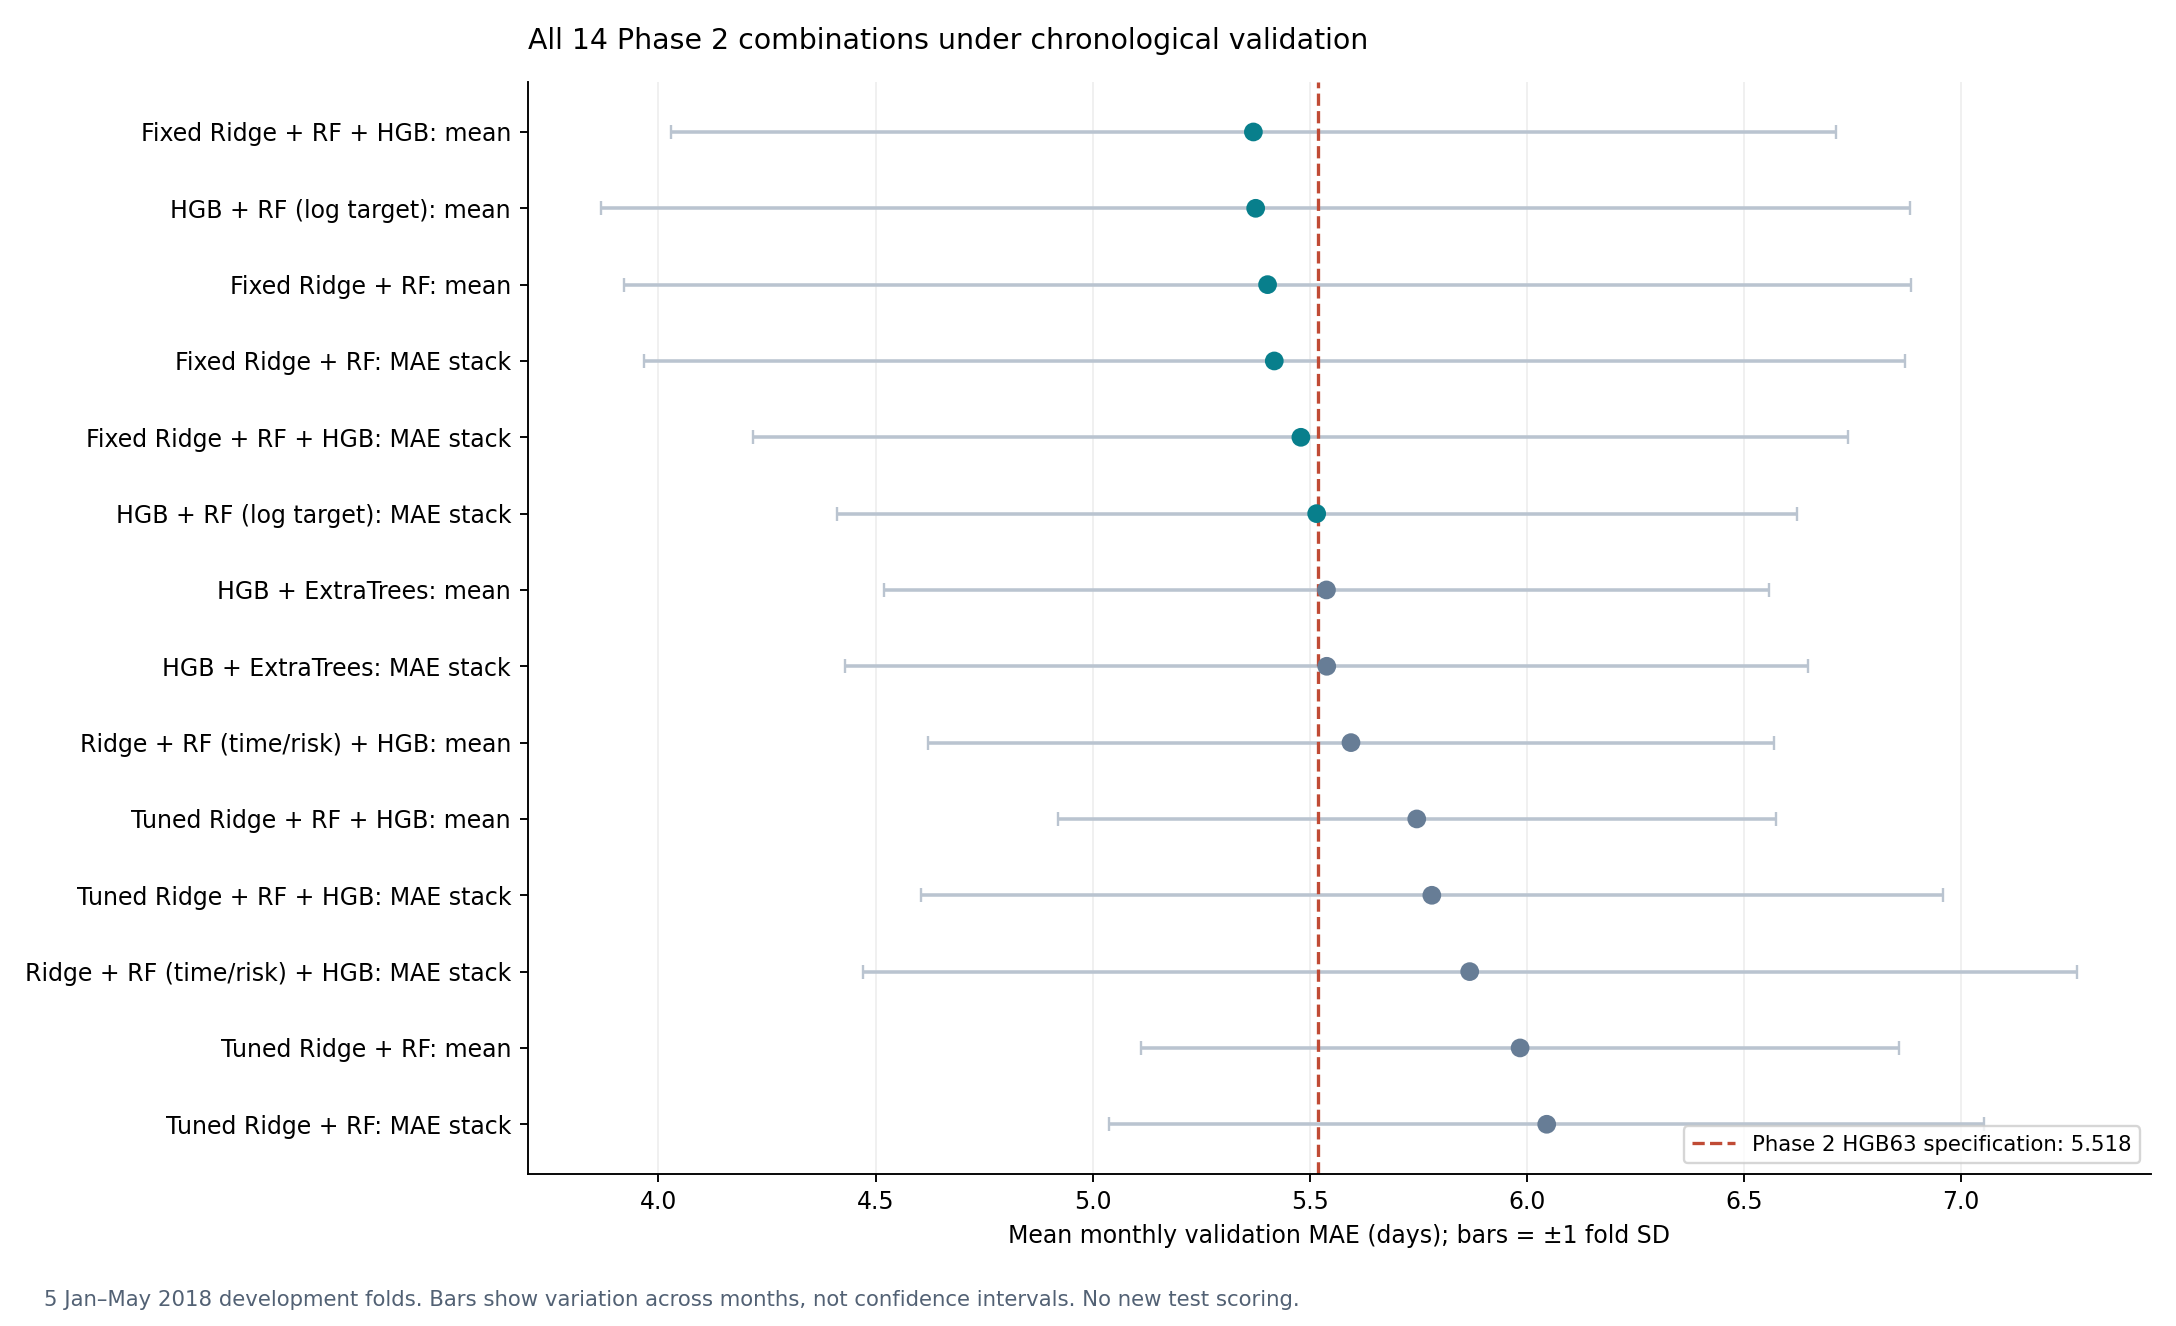

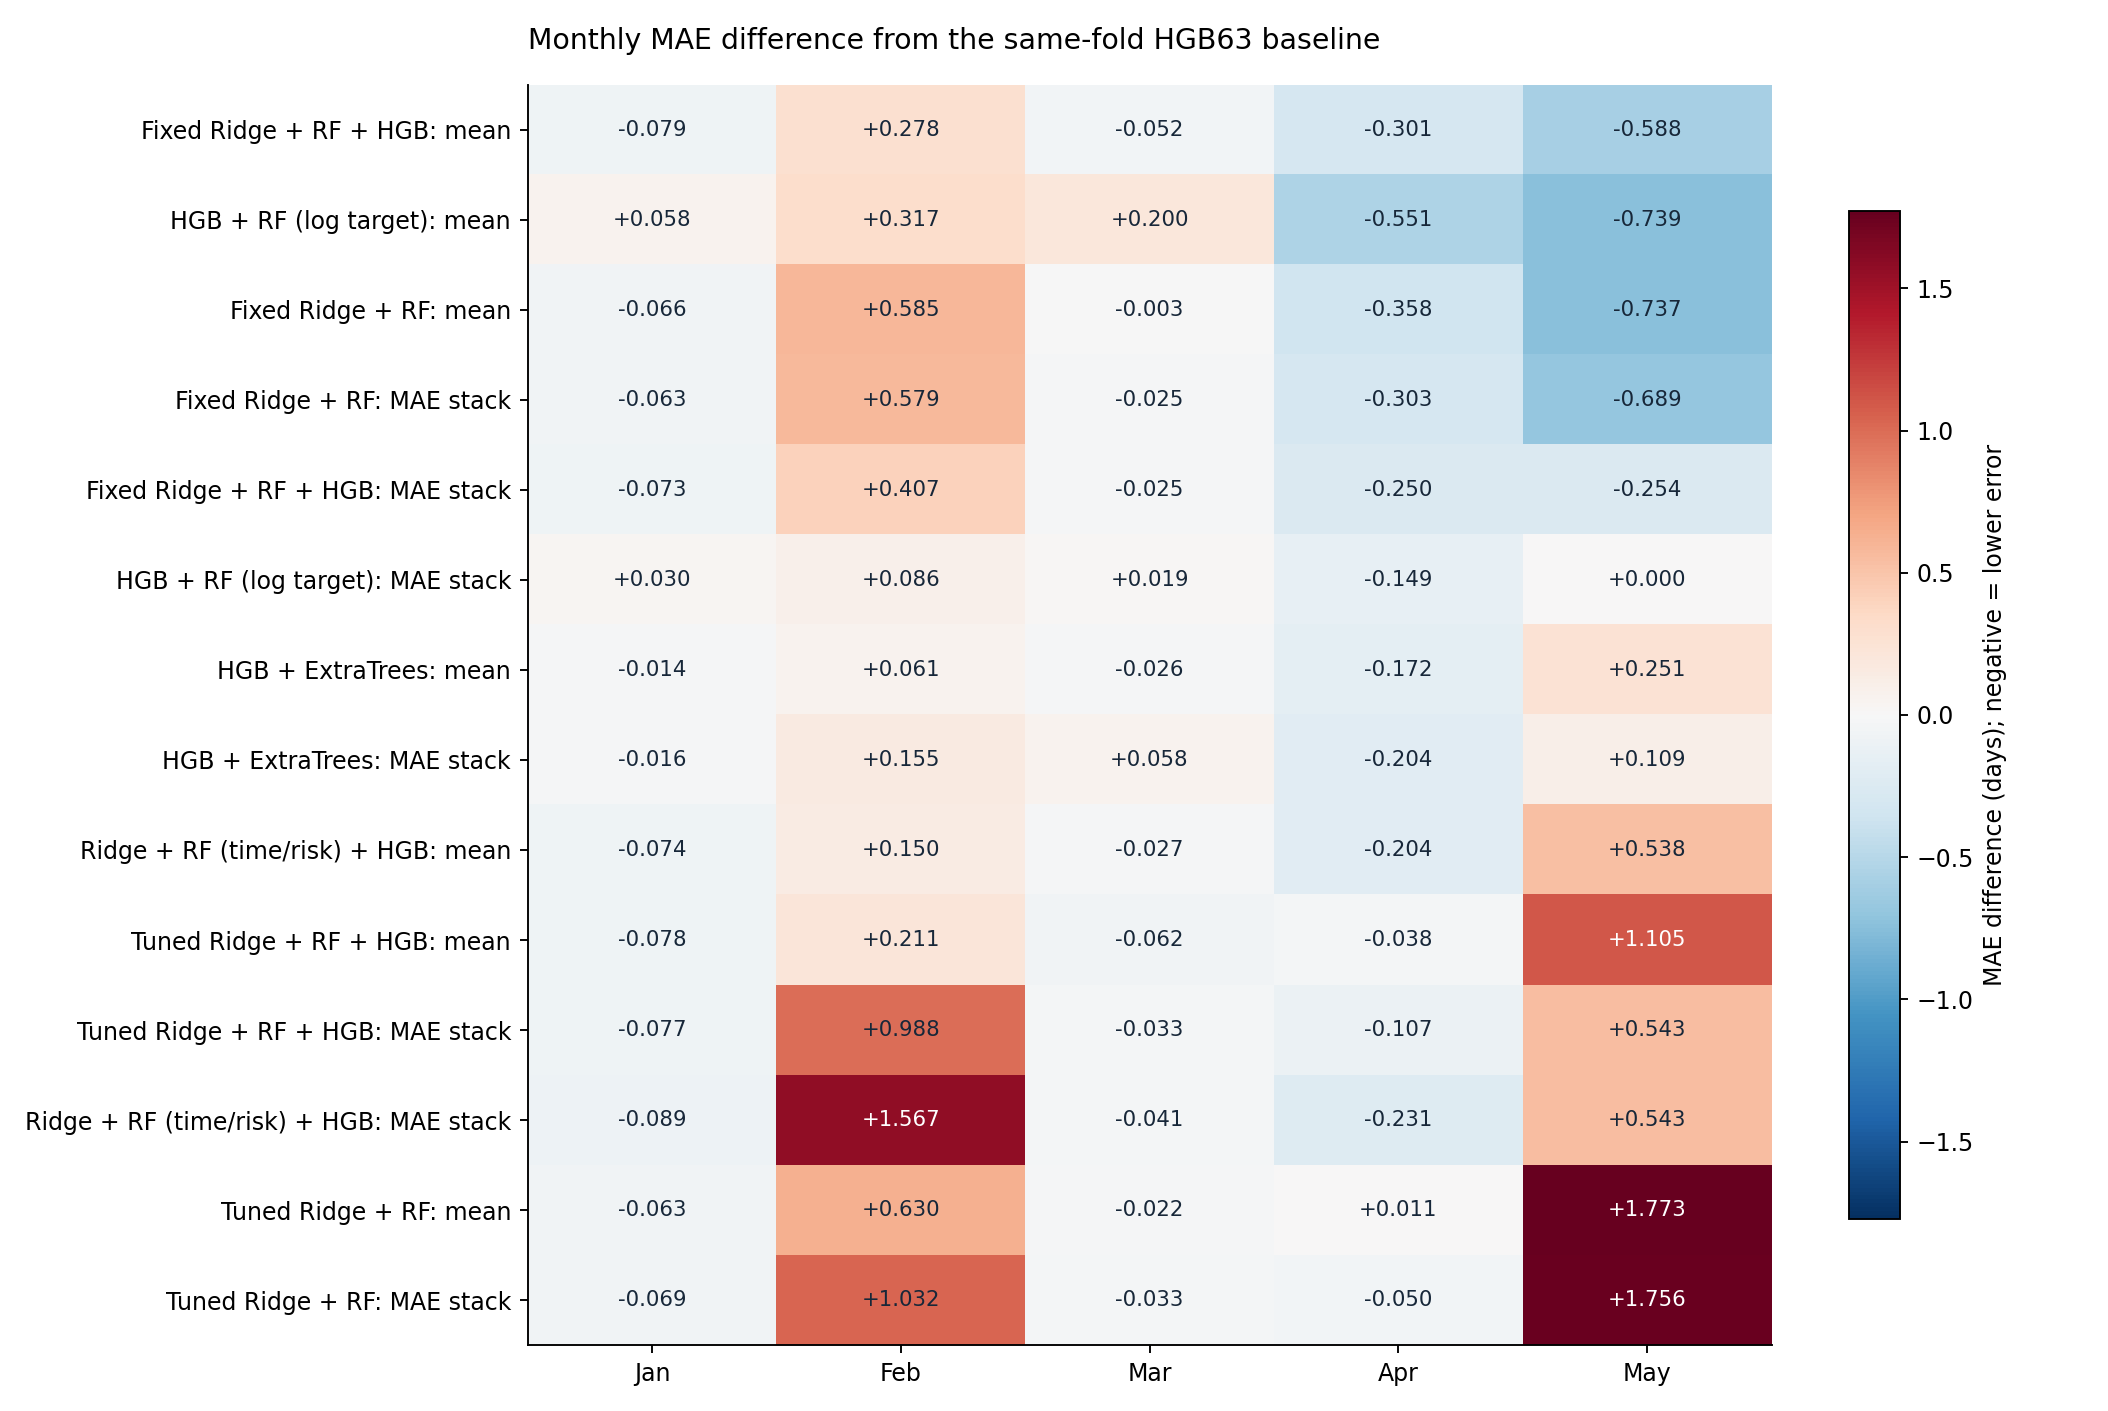

In [3]:
columns = ['candidate', 'role', 'cv_mae', 'cv_sd', 'pooled_cv_mae', 'cv_rmse',
           'pooled_cv_rmse', 'cv_n', 'train_mae', 'meta_training_mae', 'phase2_random_cv_mae']
display(report[columns])
display(Image(filename=str(out / 'figures/01_all_14_chronological_mae.png')))
display(Image(filename=str(out / 'figures/02_monthly_paired_mae.png')))


## Learned weights and candidate choices

MAE stacks use nonnegative weights summing to one and no intercept. Zero weight is valid; a stack may reduce to one member. Fixed candidate baselines and equal means have no new parameter search. Tuned Ridge/RF and ExtraTrees target representation are selected inside each outer training partition using mean inner monthly MAE; candidate order resolves exact ties.


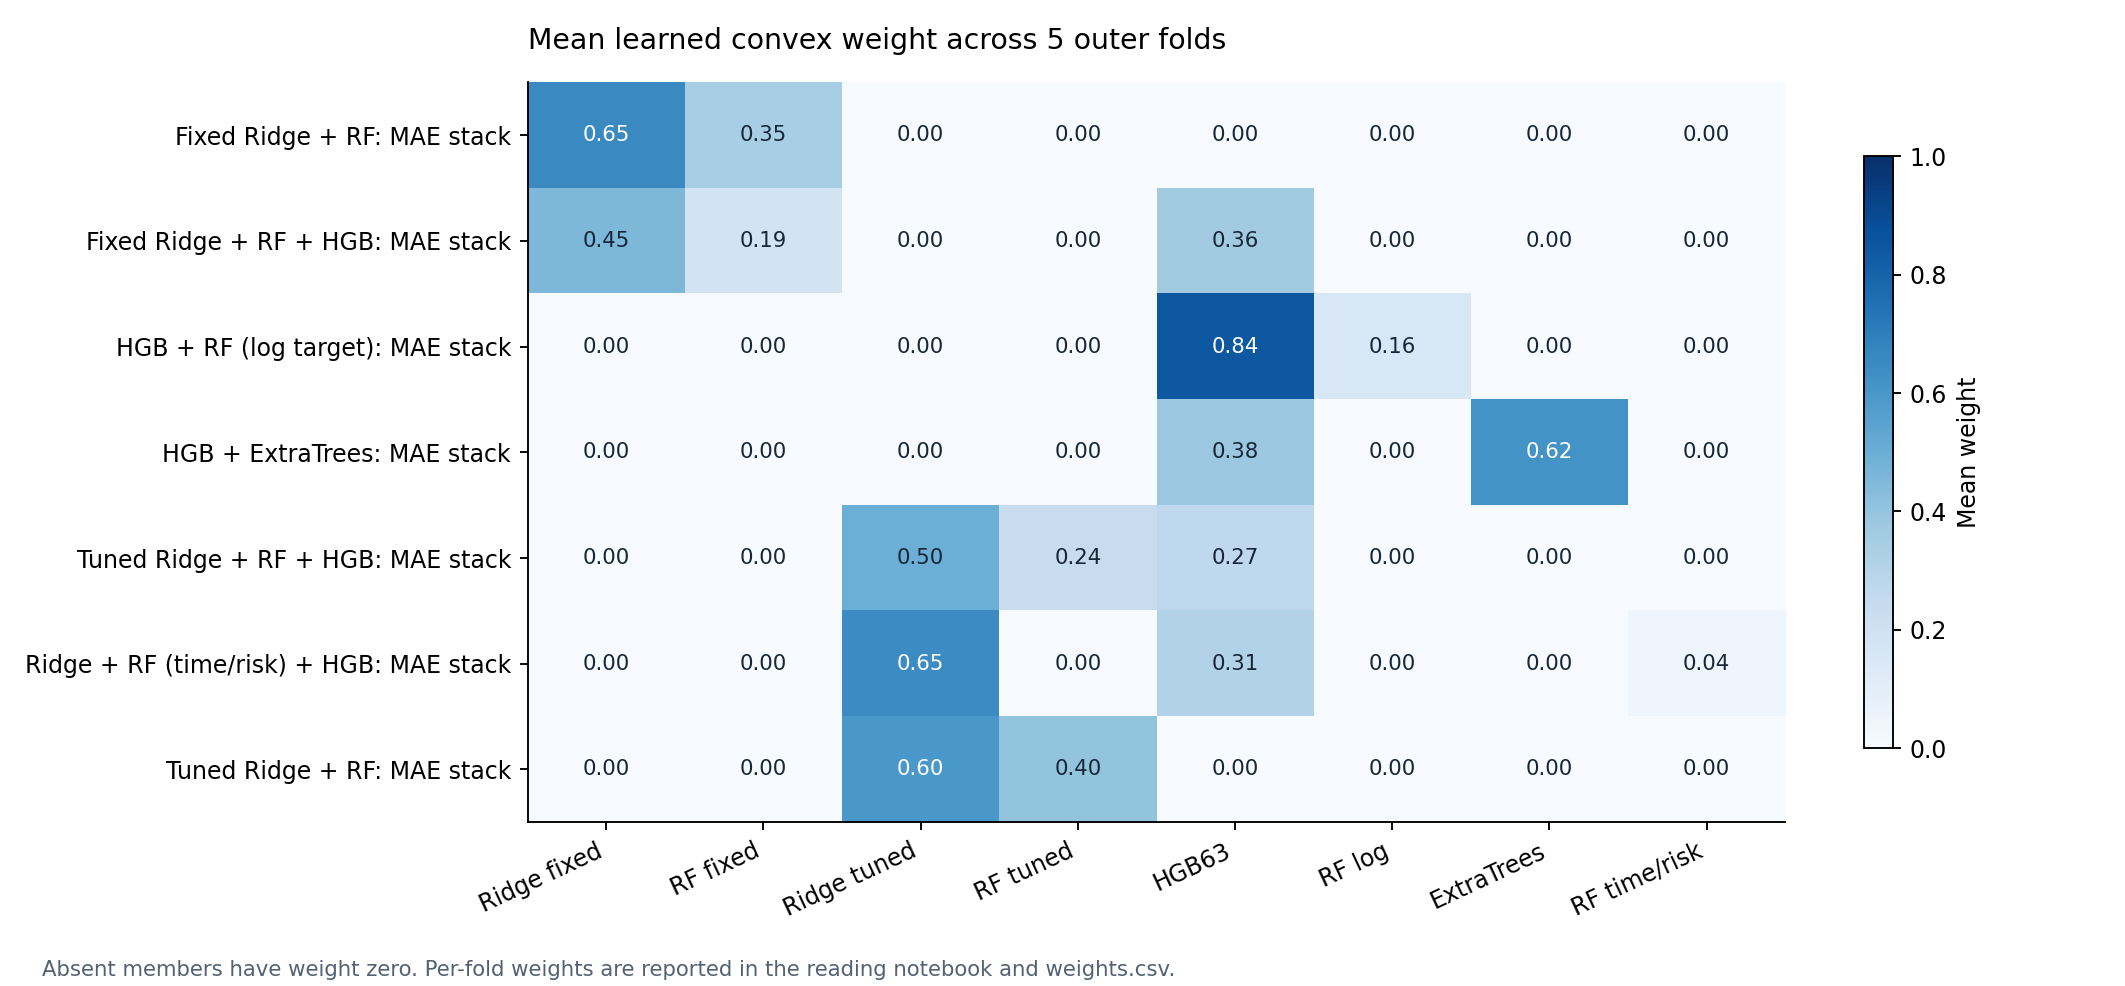

member                       extra_trees  forest_fixed  forest_tuned    hgb  \
candidate             fold                                                    
stack_hgb_extra_trees fold1       0.4819        0.0000        0.0000 0.5181   
                      fold2       0.7634        0.0000        0.0000 0.2366   
                      fold3       0.8764        0.0000        0.0000 0.1236   
                      fold4       0.7141        0.0000        0.0000 0.2859   
                      fold5       0.2539        0.0000        0.0000 0.7461   
stack_hgb_rf_log      fold1       0.0000        0.0000        0.0000 0.6419   
                      fold2       0.0000        0.0000        0.0000 0.7646   
                      fold3       0.0000        0.0000        0.0000 0.9245   
                      fold4       0.0000        0.0000        0.0000 0.8881   
                      fold5       0.0000        0.0000        0.0000 1.0000   
stack_three_fixed     fold1       0.0000        0.1905        0.0000 0.5353   
                      fold2       0.0000        0.3124        0.0000 0.1743   
                      fold3       0.0000        0.3235        0.0000 0.0000   
                      fold4       0.0000        0.0992        0.0000 0.3395   
                      fold5       0.0000        0.0000        0.0000 0.7532   
stack_three_rf_risk   fold1       0.0000        0.0000        0.0000 0.4809   
                      fold2       0.0000        0.0000        0.0000 0.1203   
                      fold3       0.0000        0.0000        0.0000 0.0831   
                      fold4       0.0000        0.0000        0.0000 0.2164   
                      fold5       0.0000        0.0000        0.0000 0.6468   
stack_three_tuned     fold1       0.0000        0.0000        0.2521 0.4490   
                      fold2       0.0000        0.0000        0.3176 0.0232   
                      fold3       0.0000        0.0000        0.3511 0.0000   
                      fold4       0.0000        0.0000        0.2562 0.2165   
                      fold5       0.0000        0.0000        0.0000 0.6468   
stack_two_fixed       fold1       0.0000        0.5434        0.0000 0.0000   
                      fold2       0.0000        0.4087        0.0000 0.0000   
                      fold3       0.0000        0.3235        0.0000 0.0000   
                      fold4       0.0000        0.2285        0.0000 0.0000   
                      fold5       0.0000        0.2287        0.0000 0.0000   
stack_two_tuned       fold1       0.0000        0.0000        0.3249 0.0000   
                      fold2       0.0000        0.0000        0.3281 0.0000   
                      fold3       0.0000        0.0000        0.3511 0.0000   
                      fold4       0.0000        0.0000        0.3970 0.0000   
                      fold5       0.0000        0.0000        0.5970 0.0000   

member                       rf_log  rf_time_risk  ridge_fixed  ridge_tuned  
candidate             fold                                                   
stack_hgb_extra_trees fold1  0.0000        0.0000       0.0000       0.0000  
                      fold2  0.0000        0.0000       0.0000       0.0000  
                      fold3  0.0000        0.0000       0.0000       0.0000  
                      fold4  0.0000        0.0000       0.0000       0.0000  
                      fold5  0.0000        0.0000       0.0000       0.0000  
stack_hgb_rf_log      fold1  0.3581        0.0000       0.0000       0.0000  
                      fold2  0.2354        0.0000       0.0000       0.0000  
                      fold3  0.0755        0.0000       0.0000       0.0000  
                      fold4  0.1119        0.0000       0.0000       0.0000  
                      fold5  0.0000        0.0000       0.0000       0.0000  
stack_three_fixed     fold1  0.0000        0.0000       0.2742       0.0000  
                      fold2  0.0000        0.0000       0.5133

,outer,family,candidate,inner_monthly_mae
3,fold1,Ridge,ridge_F0_log_a100,3.9983
14,fold1,RF,forest_F0_2,4.0525
19,fold1,ExtraTrees,extra_trees_F1_time_log,4.0206
29,fold2,Ridge,ridge_F1_time_log_a100,5.1840
35,fold2,RF,forest_F1_time_0,5.2415
38,fold2,ExtraTrees,extra_trees_F1_time_raw,5.2772
44,fold3,Ridge,ridge_F0_log_a1000,5.4782
54,fold3,RF,forest_F0_2,5.5232
58,fold3,ExtraTrees,extra_trees_F1_time_raw,5.5608
64,fold4,Ridge,ridge_F0_log_a1000,5.5287


In [4]:
display(Image(filename=str(out / 'figures/03_mean_stack_weights.png')))
display(weights[weights.candidate.str.startswith('stack_')].pivot_table(
    index=['candidate', 'fold'], columns='member', values='weight', fill_value=0))
selection = pd.read_csv(tables / 'candidate_selection.csv')
display(selection[selection.selected][['outer', 'family', 'candidate', 'inner_monthly_mae']])


## Full feature catalogue

This table lists every input family in the rerun, including all individual purchase-extension fields. `F0` includes the purchase calendar one-hot fields. `F1` adds cyclic/interaction arithmetic and `state_route`; `F1_time` also adds elapsed purchase days and a training-only year-month dictionary. The elapsed-day origin is fixed at 1 January 2016. The HGB63 member has the purchase extension, time encoding and learned risk; the RF time/risk member has F1, time and risk without the purchase extension in its regression inputs.

The risk classifier itself uses F1 plus the purchase extension and learns whether delivery exceeded 30 days from strictly available historical outcomes. Cold-start training rows receive probability zero plus `risk_unavailable=1`; scoring uses a classifier fitted on the eligible past partition. The catalogue names the resulting array columns semantically; these do not add a future outcome column to a purchase feature table. Archived product, seller and geography fields retain the source availability assumptions documented in Phase 3.


In [5]:
display(pd.read_csv(tables / 'feature_catalogue.csv'))

,feature,type,group,definition,source_or_availability,used_by,target_derived
0,promised_lead_time_days,numeric,base purchase,(estimated delivery date - purchase timestamp) / 86400 seconds,purchase / quote / static product and geography,"F0,F1,F1_time,HGB_time_risk,RF_time_risk",False
1,max_distance_km,numeric,base purchase,"Maximum seller-to-customer route distance across order items, in km",purchase / quote / static product and geography,"F0,F1,F1_time,HGB_time_risk,RF_time_risk",False
2,total_price,numeric,base purchase,Sum of item prices within the order,purchase / quote / static product and geography,"F0,F1,F1_time,HGB_time_risk,RF_time_risk",False
3,total_freight,numeric,base purchase,Sum of item freight values within the order,purchase / quote / static product and geography,"F0,F1,F1_time,HGB_time_risk,RF_time_risk",False
4,freight_ratio,numeric,base purchase,Total freight / total item price; missing when total price is nonpositive,purchase / quote / static product and geography,"F0,F1,F1_time,HGB_time_risk,RF_time_risk",False
5,item_count,numeric,base purchase,Number of order-item records,purchase / quote / static product and geography,"F0,F1,F1_time,HGB_time_risk,RF_time_risk",False
6,seller_count,numeric,base purchase,Number of distinct sellers in the order,purchase / quote / static product and geography,"F0,F1,F1_time,HGB_time_risk,RF_time_risk",False
7,avg_product_weight_g,numeric,base purchase,Mean positive item product weight; missing if any item weight is unavailable,purchase / quote / static product and geography,"F0,F1,F1_time,HGB_time_risk,RF_time_risk",False
8,any_distance_missing,numeric,base purchase,Indicator that at least one item route has unavailable coordinates/distance,purchase / quote / static product and geography,"F0,F1,F1_time,HGB_time_risk,RF_time_risk",False
9,any_weight_missing,numeric,base purchase,Indicator that at least one item product weight is unavailable or nonpositive,purchase / quote / static product and geography,"F0,F1,F1_time,HGB_time_risk,RF_time_risk",False


## Full model specifications and bounded search ranges

The original bounded search contains **12 Ridge**, **six RF** and **two ExtraTrees** candidates. The fixed-role table includes the exact HGB63 specification and each RF variant; duplicates with searched candidates are shared computationally. Original-day predictions are used for all combination weights and scores. Log-target learners fit `log1p(y)` and return nonnegative `expm1` predictions. HGB early stopping is disabled.


In [6]:
specs = pd.read_csv(tables / 'model_specifications.csv')
for group in ['Ridge search', 'RF search', 'ExtraTrees search', 'Fixed role', 'Risk classifier']:
    print(group)
    display(specs[specs.group.eq(group)].drop(columns='group'))


Ridge search


,role,candidate,kind,feature_pack,time,risk,purchase_extension,log_inputs,log_target,parameters
0,candidate,ridge_F0_raw_a100,ridge,F0,False,False,False,False,False,"{""alpha"": 100, ""copy_X"": true, ""fit_intercept"": true, ""max_iter"": null, ""positive"": false, ""random_state"": null, ""solver"": ""auto"", ""tol"": 0.0001}"
1,candidate,ridge_F0_raw_a1000,ridge,F0,False,False,False,False,False,"{""alpha"": 1000, ""copy_X"": true, ""fit_intercept"": true, ""max_iter"": null, ""positive"": false, ""random_state"": null, ""solver"": ""auto"", ""tol"": 0.0001}"
2,candidate,ridge_F0_raw_a10000,ridge,F0,False,False,False,False,False,"{""alpha"": 10000, ""copy_X"": true, ""fit_intercept"": true, ""max_iter"": null, ""positive"": false, ""random_state"": null, ""solver"": ""auto"", ""tol"": 0.0001}"
3,candidate,ridge_F0_log_a100,ridge,F0,False,False,False,True,False,"{""alpha"": 100, ""copy_X"": true, ""fit_intercept"": true, ""max_iter"": null, ""positive"": false, ""random_state"": null, ""solver"": ""auto"", ""tol"": 0.0001}"
4,candidate,ridge_F0_log_a1000,ridge,F0,False,False,False,True,False,"{""alpha"": 1000, ""copy_X"": true, ""fit_intercept"": true, ""max_iter"": null, ""positive"": false, ""random_state"": null, ""solver"": ""auto"", ""tol"": 0.0001}"
5,candidate,ridge_F0_log_a10000,ridge,F0,False,False,False,True,False,"{""alpha"": 10000, ""copy_X"": true, ""fit_intercept"": true, ""max_iter"": null, ""positive"": false, ""random_state"": null, ""solver"": ""auto"", ""tol"": 0.0001}"
6,candidate,ridge_F1_time_raw_a100,ridge,F1_time,True,False,False,False,False,"{""alpha"": 100, ""copy_X"": true, ""fit_intercept"": true, ""max_iter"": null, ""positive"": false, ""random_state"": null, ""solver"": ""auto"", ""tol"": 0.0001}"
7,candidate,ridge_F1_time_raw_a1000,ridge,F1_time,True,False,False,False,False,"{""alpha"": 1000, ""copy_X"": true, ""fit_intercept"": true, ""max_iter"": null, ""positive"": false, ""random_state"": null, ""solver"": ""auto"", ""tol"": 0.0001}"
8,candidate,ridge_F1_time_raw_a10000,ridge,F1_time,True,False,False,False,False,"{""alpha"": 10000, ""copy_X"": true, ""fit_intercept"": true, ""max_iter"": null, ""positive"": false, ""random_state"": null, ""solver"": ""auto"", ""tol"": 0.0001}"
9,candidate,ridge_F1_time_log_a100,ridge,F1_time,True,False,False,True,False,"{""alpha"": 100, ""copy_X"": true, ""fit_intercept"": true, ""max_iter"": null, ""positive"": false, ""random_state"": null, ""solver"": ""auto"", ""tol"": 0.0001}"


RF search


,role,candidate,kind,feature_pack,time,risk,purchase_extension,log_inputs,log_target,parameters
12,candidate,forest_F0_0,forest,F0,False,False,False,False,False,"{""bootstrap"": true, ""ccp_alpha"": 0.0, ""criterion"": ""squared_error"", ""max_depth"": 24, ""max_features"": 0.8, ""max_leaf_nodes"": null, ""max_samples"": 0.8, ""min_impurity_decrease"": 0.0, ""min_samples_leaf"": 10, ""min_samples_split"": 2, ""min_weight_fraction_leaf"": 0.0, ""monotonic_cst"": null, ""n_estimators"": 100, ""n_jobs"": 4, ""oob_score"": false, ""random_state"": 33, ""verbose"": 0, ""warm_start"": false}"
13,candidate,forest_F0_1,forest,F0,False,False,False,False,False,"{""bootstrap"": true, ""ccp_alpha"": 0.0, ""criterion"": ""squared_error"", ""max_depth"": null, ""max_features"": 0.8, ""max_leaf_nodes"": null, ""max_samples"": 0.8, ""min_impurity_decrease"": 0.0, ""min_samples_leaf"": 5, ""min_samples_split"": 2, ""min_weight_fraction_leaf"": 0.0, ""monotonic_cst"": null, ""n_estimators"": 100, ""n_jobs"": 4, ""oob_score"": false, ""random_state"": 33, ""verbose"": 0, ""warm_start"": false}"
14,candidate,forest_F0_2,forest,F0,False,False,False,False,False,"{""bootstrap"": true, ""ccp_alpha"": 0.0, ""criterion"": ""squared_error"", ""max_depth"": 16, ""max_features"": 0.6, ""max_leaf_nodes"": null, ""max_samples"": 0.8, ""min_impurity_decrease"": 0.0, ""min_samples_leaf"": 20, ""min_samples_split"": 2, ""min_weight_fraction_leaf"": 0.0, ""monotonic_cst"": null, ""n_estimators"": 100, ""n_jobs"": 4, ""oob_score"": false, ""random_state"": 33, ""verbose"": 0, ""warm_start"": false}"
15,candidate,forest_F1_time_0,forest,F1_time,True,False,False,False,False,"{""bootstrap"": true, ""ccp_alpha"": 0.0, ""criterion"": ""squared_error"", ""max_depth"": 24, ""max_features"": 0.8, ""max_leaf_nodes"": null, ""max_samples"": 0.8, ""min_impurity_decrease"": 0.0, ""min_samples_leaf"": 10, ""min_samples_split"": 2, ""min_weight_fraction_leaf"": 0.0, ""monotonic_cst"": null, ""n_estimators"": 100, ""n_jobs"": 4, ""oob_score"": false, ""random_state"": 33, ""verbose"": 0, ""warm_start"": false}"
16,candidate,forest_F1_time_1,forest,F1_time,True,False,False,False,False,"{""bootstrap"": true, ""ccp_alpha"": 0.0, ""criterion"": ""squared_error"", ""max_depth"": null, ""max_features"": 0.8, ""max_leaf_nodes"": null, ""max_samples"": 0.8, ""min_impurity_decrease"": 0.0, ""min_samples_leaf"": 5, ""min_samples_split"": 2, ""min_weight_fraction_leaf"": 0.0, ""monotonic_cst"": null, ""n_estimators"": 100, ""n_jobs"": 4, ""oob_score"": false, ""random_state"": 33, ""verbose"": 0, ""warm_start"": false}"
17,candidate,forest_F1_time_2,forest,F1_time,True,False,False,False,False,"{""bootstrap"": true, ""ccp_alpha"": 0.0, ""criterion"": ""squared_error"", ""max_depth"": 16, ""max_features"": 0.6, ""max_leaf_nodes"": null, ""max_samples"": 0.8, ""min_impurity_decrease"": 0.0, ""min_samples_leaf"": 20, ""min_samples_split"": 2, ""min_weight_fraction_leaf"": 0.0, ""monotonic_cst"": null, ""n_estimators"": 100, ""n_jobs"": 4, ""oob_score"": false, ""random_state"": 33, ""verbose"": 0, ""warm_start"": false}"


ExtraTrees search


,role,candidate,kind,feature_pack,time,risk,purchase_extension,log_inputs,log_target,parameters
18,candidate,extra_trees_F1_time_raw,extra_trees,F1_time,True,False,False,False,False,"{""bootstrap"": false, ""ccp_alpha"": 0.0, ""criterion"": ""squared_error"", ""max_depth"": 24, ""max_features"": 0.8, ""max_leaf_nodes"": null, ""max_samples"": null, ""min_impurity_decrease"": 0.0, ""min_samples_leaf"": 10, ""min_samples_split"": 2, ""min_weight_fraction_leaf"": 0.0, ""monotonic_cst"": null, ""n_estimators"": 100, ""n_jobs"": 4, ""oob_score"": false, ""random_state"": 33, ""verbose"": 0, ""warm_start"": false}"
19,candidate,extra_trees_F1_time_log,extra_trees,F1_time,True,False,False,False,True,"{""bootstrap"": false, ""ccp_alpha"": 0.0, ""criterion"": ""squared_error"", ""max_depth"": 24, ""max_features"": 0.8, ""max_leaf_nodes"": null, ""max_samples"": null, ""min_impurity_decrease"": 0.0, ""min_samples_leaf"": 10, ""min_samples_split"": 2, ""min_weight_fraction_leaf"": 0.0, ""monotonic_cst"": null, ""n_estimators"": 100, ""n_jobs"": 4, ""oob_score"": false, ""random_state"": 33, ""verbose"": 0, ""warm_start"": false}"


Fixed role


,role,candidate,kind,feature_pack,time,risk,purchase_extension,log_inputs,log_target,parameters
20,ridge_fixed,ridge_F0_log_a1000,ridge,F0,False,False,False,True,False,"{""alpha"": 1000, ""copy_X"": true, ""fit_intercept"": true, ""max_iter"": null, ""positive"": false, ""random_state"": null, ""solver"": ""auto"", ""tol"": 0.0001}"
21,forest_fixed,forest_F0_0,forest,F0,False,False,False,False,False,"{""bootstrap"": true, ""ccp_alpha"": 0.0, ""criterion"": ""squared_error"", ""max_depth"": 24, ""max_features"": 0.8, ""max_leaf_nodes"": null, ""max_samples"": 0.8, ""min_impurity_decrease"": 0.0, ""min_samples_leaf"": 10, ""min_samples_split"": 2, ""min_weight_fraction_leaf"": 0.0, ""monotonic_cst"": null, ""n_estimators"": 100, ""n_jobs"": 4, ""oob_score"": false, ""random_state"": 33, ""verbose"": 0, ""warm_start"": false}"
22,hgb,leaves63__time_risk,hist_boost,F1,True,True,True,False,False,"{""categorical_features"": ""from_dtype"", ""early_stopping"": false, ""interaction_cst"": null, ""l2_regularization"": 10, ""learning_rate"": 0.05, ""loss"": ""absolute_error"", ""max_bins"": 255, ""max_depth"": null, ""max_features"": 1.0, ""max_iter"": 300, ""max_leaf_nodes"": 63, ""min_samples_leaf"": 30, ""monotonic_cst"": null, ""n_iter_no_change"": 10, ""quantile"": null, ""random_state"": 33, ""scoring"": ""loss"", ""tol"": 1e-07, ""validation_fraction"": 0.1, ""verbose"": 0, ""warm_start"": false}"
23,rf_log,rf_log_F1,forest,F1,False,False,False,False,True,"{""bootstrap"": true, ""ccp_alpha"": 0.0, ""criterion"": ""squared_error"", ""max_depth"": 24, ""max_features"": 0.8, ""max_leaf_nodes"": null, ""max_samples"": 0.8, ""min_impurity_decrease"": 0.0, ""min_samples_leaf"": 10, ""min_samples_split"": 2, ""min_weight_fraction_leaf"": 0.0, ""monotonic_cst"": null, ""n_estimators"": 100, ""n_jobs"": 4, ""oob_score"": false, ""random_state"": 33, ""verbose"": 0, ""warm_start"": false}"
24,rf_time_risk,rf_log_F1_time_risk,forest,F1,True,True,False,False,True,"{""bootstrap"": true, ""ccp_alpha"": 0.0, ""criterion"": ""squared_error"", ""max_depth"": 24, ""max_features"": 0.8, ""max_leaf_nodes"": null, ""max_samples"": 0.8, ""min_impurity_decrease"": 0.0, ""min_samples_leaf"": 10, ""min_samples_split"": 2, ""min_weight_fraction_leaf"": 0.0, ""monotonic_cst"": null, ""n_estimators"": 100, ""n_jobs"": 4, ""oob_score"": false, ""random_state"": 33, ""verbose"": 0, ""warm_start"": false}"


Risk classifier


,role,candidate,kind,feature_pack,time,risk,purchase_extension,log_inputs,log_target,parameters
25,historical slow-delivery feature,HGBClassifier_gt30days,hist_classifier,F1 plus purchase extension,False,False,True,False,False,"{""categorical_features"": ""from_dtype"", ""class_weight"": null, ""early_stopping"": false, ""interaction_cst"": null, ""l2_regularization"": 10.0, ""learning_rate"": 0.05, ""loss"": ""log_loss"", ""max_bins"": 255, ""max_depth"": null, ""max_features"": 1.0, ""max_iter"": 200, ""max_leaf_nodes"": 15, ""min_samples_leaf"": 40, ""monotonic_cst"": null, ""n_iter_no_change"": 10, ""random_state"": 33, ""scoring"": ""loss"", ""tol"": 1e-07, ""validation_fraction"": 0.1, ""verbose"": 0, ""warm_start"": false}"


## Audit and interpretation limits

The report verifies strict time boundaries, zero train/score overlap, nonnegative unit-sum weights, all 14 combinations on the same five outer folds, and unchanged protected main regression/classification outputs. The figures summarize development results and do not establish an independent deployment improvement. The original Phase 3 model decision remains frozen.

The source code and frozen candidate registry are in `src/regression_stacking/` and `outputs/regression_stacking_chronological/protocol.json`. The original 14 random-fold aggregate results remain in Phase 2. Individual order predictions and fitting caches stay under ignored data paths.


In [7]:
verification = json.loads((out / 'report_verification.json').read_text())
display(verification)
independent = json.loads((out / 'verification.json').read_text())
print('Independent prediction and weight replay:')
display(independent)


{'verified_at': '2026-10-30T10:58:58.084192+00:00',
 'preview': False,
 'outer_folds': 5,
 'combinations': 14,
 'all_14_combination_fold_rows': 70,
 'feature_catalogue_rows': 49,
 'model_specification_rows': 26,
 'zero_future_training_labels': True,
 'zero_unavailable_meta_labels': True,
 'convex_weight_sums_verified': True,
 'train_score_disjoint': True,
 'test_evaluations': 0,
 'protected_main_evidence_unchanged': True,
 'original_training_table_sha256': {'outer_fold_metrics': 'c62cd710ecad1a8aa3638174defa5d54b63a7f8ae6c43ae01fad68bbed26e097',
  'comparison': '3d11b31d542ccd1d2de6c424f343b592e176d18e7e60283db60388fa804a0f2c',
  'weights': 'f21d51b57d9f9353e9f9dd7efccf250b70241f17706006555a61287cc056be4d',
  'candidate_selection': '8a14afebab09aebbce8bc7ac51f931eb5d01168d54c5ef1a63f159d3d631291c',
  'time_audit': '27fdd2fc6b0ab3111f72709cec06cf8cbac8ad82c11331de3a6196b68127e43a'},
 'protocol_sha256': 'eade5bc0a0b682b82fff5bb8109bf3e85eab5eaebbe0dafc176b7353f59b7631',
 'report_builder_

Independent prediction and weight replay:


{'checked_at': '2026-10-30T10:58:01.467048+00:00',
 'verifier_sha256': '5fb1270c9c832ecbd0cff1dfffdbf4d66c3dad89c83db18166399739e3988d6e',
 'status': 'passed',
 'passed': True,
 'completed_folds': 5,
 'expected_folds': 5,
 'base_prediction_cache_checks': 385,
 'feature_matrix_identity_checks': 385,
 'risk_partition_checks': 470,
 'inner_candidate_evaluations': 345,
 'combination_fold_checks': 70,
 'weight_dual_certificates': 35,
 'unique_risk_models_checked': 21,
 'unique_risk_feature_matrices_checked': 40,
 'max_weight_primal_dual_gap_days': 4.1744385725905886e-14,
 'phase2_fidelity': {'exact_classic_preprocessing_matrices': 4,
  'exact_extension_preprocessing_matrices': 1,
  'field_order_verified': True,
  'hgb_and_risk_parameters_verified': True,
  'ridge_candidates': 12,
  'forest_candidates': 6,
  'sample_rows': 1200},
 'protected_files_verified': 89,
 'frozen_sources_verified': 8,
 'course_members_verified': 7,
 'development_orders_verified': 77600,
 'test_evaluations': 0,
 'vali